# Bayesian Experimental Design with BayesFlow and PyTorch

_Author: Desi R. Ivanova_

Which measurements would teach us the most about a system? Bayesian experimental design chooses experiments that reduce uncertainty about its parameters.

We will choose seven substrate concentrations for an enzyme reaction. A BayesFlow coupling flow learns the posterior, while PyTorch differentiates through the simulator to improve the concentrations. We first train with fixed designs, then learn the designs together with the posterior.

This tutorial uses a custom training loop. It requires the PyTorch backend and uses a GPU when available. No external sampler is needed: with two parameters, we can check the posterior on a numerical grid.

## Short intro to BED

(_For a longer, more comprehensive overview, please see [1] or [2], or [this blogpost](https://desirivanova.com/post/boed-intro/) for a slightly longer introduction._)

BED is a model-based approach to designing optimal experiments.
We start with a Bayesian model (or simulator) $p(\theta)\,p(y \mid \xi, \theta)$ of the underlying process we're interested in.
The model has parameters $\theta$ with prior $p(\theta)$: these are the quantities we'd like to learn or infer.
The data model $p(y \mid \xi, \theta)$ describes (or simulates) how the data $y$ are generated given the parameters $\theta$ and the design variables $\xi$.

The optimal design $\xi^*$ is the one that maximises the expected information gain (EIG) about the parameters $\theta$.
The EIG is the expected reduction in Shannon entropy from the prior $p(\theta)$ to the posterior $p(\theta \mid y, \xi)$ that results from the experiment with design $\xi$:

$$
\text{EIG}_\theta(\xi) = H[p(\theta)] - \mathbb{E}_{p(y \mid \xi)} \big[ H[p(\theta \mid y, \xi)] \big] = I(\theta; y \mid \xi).
$$

The EIG is equivalent to the mutual information (MI) between the parameters and the outcomes for a given design.
With some Bayes rule gymnastics, we can write the EIG in the following equivalent forms:

$$
\text{EIG}(\xi) = \mathbb{E}_{p(\theta, y \mid \xi)} \left[ \log \frac{p(\theta, y \mid \xi)}{p(\theta)p(y \mid \xi)} \right] =  \mathbb{E}_{p(\theta, y \mid \xi)} \left[ \log \frac{p(y \mid  \theta, \xi)}{p(y \mid \xi)} \right] = \mathbb{E}_{p(\theta, y \mid \xi)} \left[ \log \frac{p(\theta \mid y, \xi)}{p(\theta)} \right].
$$

In general, the EIG is difficult to estimate and optimise regardless of which form we pick: we either have to deal with an expectation of a non-linear function ($\log$) of the intractable marginal $p(y \mid \xi)$, or alternatively with an intractable posterior $p(\theta \mid y, \xi)$.

In this tutorial we are going to use the Barber-Agakov estimator [3, 4]---a popular variational lower bound on the mutual information:

$$
\mathcal{L}(\xi, q) :=  \mathbb{E}_{p(\theta, y \mid \xi)} \left[ \log \frac{q(\theta \mid y, \xi)}{p(\theta)} \right] \leq I(\theta; y \mid \xi),
$$

where $q(\cdot)$ is any distribution over the parameters $\theta$. The optimal $q(\cdot)$, which makes the bound tight, is the true posterior $p(\theta \mid y, \xi)$.

Notice that the prior $p(\theta)$ is independent of the designs $\xi$ and the variational distribution $q(\theta \mid y, \xi)$, so maximising the objective $\mathcal{L}(\xi, q)$ is equivalent to minimising:

$$
\mathcal{J}(\xi, q) := -\mathbb{E}_{p(\theta, y \mid \xi)} \big[ \log q(\theta \mid y, \xi)\big],
$$

which is very similar to the standard cross-entropy objective we use to train our neural posterior estimators (NPEs)! The **key difference** is that we are now also optimising over the designs $\xi$, which also appear in the expectation. We can use the [reparameterisation trick](https://en.wikipedia.org/wiki/Reparameterization_trick) to optimise $\xi$ jointly with the parameters of our neural posterior estimator $q(\cdot)$.

Let's see how this works in practice!


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import torch
import torch.distributions as dist
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import trange

import bayesflow as bf

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on {device}")

INFO:bayesflow:Using backend 'torch'


When using torch backend, we need to disable autograd by default to avoid excessive memory usage. Use

with torch.enable_grad():
    ...

in contexts where you need gradients (e.g. custom training loops).


Training on cuda


In [ ]:
colors = {"initial": "#3C5488", "optimized": "#008B8B", "reference": "#C58B39"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## Michaelis–Menten kinetics

We use a Hill-type extension of Michaelis–Menten kinetics:

$$
y_d \sim \mathcal{N}\left(\frac{(400\xi_d)^4 a}{(400\xi_d)^4 + b^4},\;5^2\right),
\qquad (a,b) = 20 + 180\theta,
\qquad \theta \sim \mathcal{N}(0.5\mathbf{1},\;0.1^2 I).
$$

Here $a$ is the maximum reaction rate and $b$ is the half-saturation concentration. The seven design variables $\xi_d\in(0,1)$ control the substrate concentrations. We optimize their logits, so the concentrations stay in range.

The simulator uses `rsample()` for the observations. This keeps the gradient from the posterior loss back to the designs. Scaling the outcomes by 200 keeps the network inputs near one.

In [2]:
class MichaelisMenten(torch.nn.Module):
    def __init__(self, design_logits, learn_designs=False):
        super().__init__()
        self.design_logits = torch.nn.Parameter(design_logits.clone(), requires_grad=learn_designs)
        self.register_buffer("prior_loc", torch.full((2,), 0.5, device=design_logits.device))

    def prior(self):
        return dist.Independent(dist.Normal(self.prior_loc, 0.1), 1)

    def mean(self, theta, concentrations=None):
        concentrations = self.design_logits.sigmoid() if concentrations is None else concentrations
        a, b = (20 + 180 * theta).unbind(-1)
        substrate = (400 * concentrations) ** 4
        return a[..., None] * substrate / (substrate + b[..., None] ** 4)

    def likelihood(self, theta):
        return dist.Independent(dist.Normal(self.mean(theta), 5.0), 1)

    def forward(self, batch_size):
        theta = self.prior().sample((batch_size,))
        y = self.likelihood(theta).rsample()
        return theta, y


initial_logits = 0.1 * torch.randn(7, device=device)
fixed_simulator = MichaelisMenten(initial_logits)
design_simulator = MichaelisMenten(initial_logits, learn_designs=True)
test_theta = fixed_simulator.prior().sample((3,))

## Learn the posterior and the designs

The same short training loop handles both cases. For fixed designs, the optimizer only updates the flow. For learned designs, it also updates the simulator's design logits.

Each gradient step uses another simulated batch. The flow receives the seven scaled observations and learns standardized parameters, `(theta - 0.5) / 0.1`. We fit a separate flow for each design, so the design itself does not need to be an input. For a posterior shared across different experiments, include the designs in `inference_conditions` too.

Validation uses held-out parameters and fixed observation noise. As the designs change, we recompute these observations at the current concentrations. The validation loss estimates the same objective on independent data.

In [3]:
validation_theta = fixed_simulator.prior().sample((1024,))
validation_noise = 5 * torch.randn(1024, 7, device=device)


@torch.enable_grad()
def train_posterior(simulator):
    posterior = bf.networks.CouplingFlow(
        depth=2, transform="spline", subnet_kwargs={"widths": [64, 64]},
    )
    posterior.build((None, 2), (None, 7))
    posterior.to(device)
    optimizer = torch.optim.Adam([
        {"params": posterior.parameters(), "lr": 1e-3},
        {"params": simulator.parameters(), "lr": 5e-3},
    ])
    history = keras.callbacks.History()
    history.history = {"loss": [], "val_loss": []}
    progress = trange(40, desc="Training")
    for epoch in progress:
        losses = []
        for _ in range(50):
            optimizer.zero_grad()
            theta, y = simulator(256)
            loss = -posterior.log_prob((theta - 0.5) / 0.1, conditions=y / 200, training=True).mean()
            loss.backward()
            optimizer.step()
            losses.append(loss.detach())
        with torch.no_grad():
            y_val = simulator.mean(validation_theta) + validation_noise
            val_loss = -posterior.log_prob((validation_theta - 0.5) / 0.1, conditions=y_val / 200).mean()
        history.history["loss"].append(torch.stack(losses).mean().item())
        history.history["val_loss"].append(val_loss.item())
        progress.set_postfix(loss=history.history["loss"][-1], val_loss=val_loss.item())
    return posterior, history


fixed_posterior, fixed_history = train_posterior(fixed_simulator)
design_posterior, design_history = train_posterior(design_simulator)

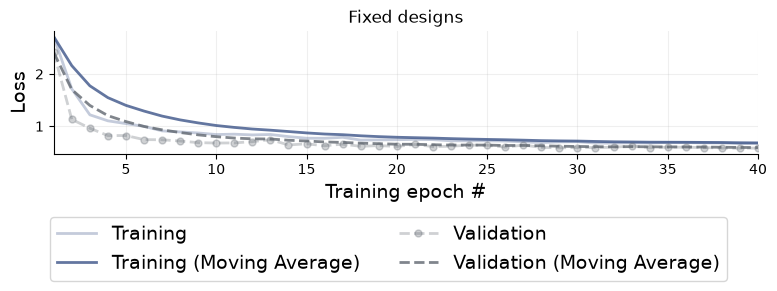

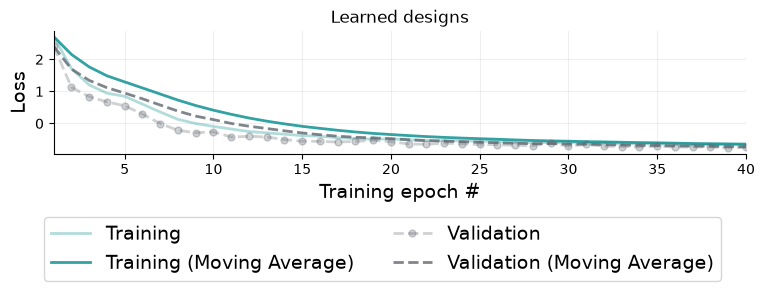

In [4]:
for title, history, color in [
    ("Fixed designs", fixed_history, colors["initial"]),
    ("Learned designs", design_history, colors["optimized"]),
]:
    fig = bf.diagnostics.loss(history, train_color=color, val_color="#606770", figsize=(8, 3))
    fig.axes[0].set_title(title)
    plt.show()

## Where should we measure?

The initial concentrations are close together. Compare them with the learned concentrations below. Measuring near the rising part of the curve helps identify the half-saturation parameter. Measuring near the plateau helps identify the maximum reaction rate.

These are the designs found by this optimization run, not a guarantee of a global optimum.

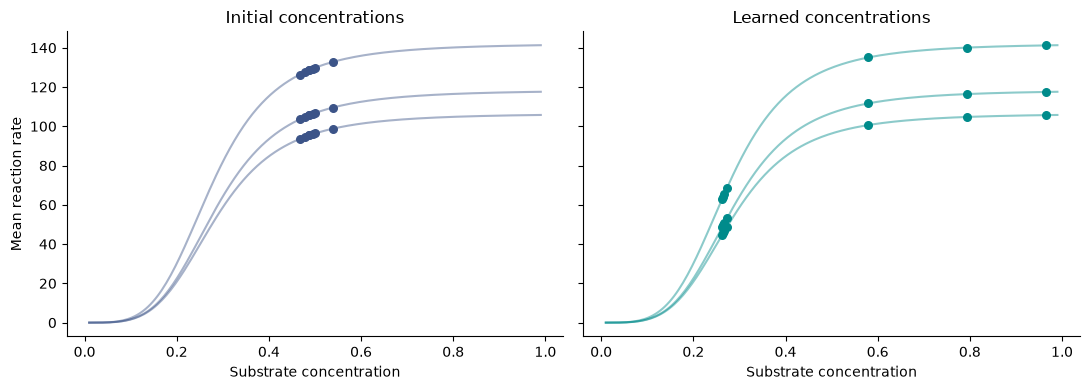

,Initial concentration,Learned concentration
0,0.467,0.263
1,0.478,0.265
2,0.487,0.267
3,0.488,0.273
4,0.496,0.580
5,0.501,0.793
6,0.538,0.966


In [5]:
concentrations = torch.linspace(0.01, 0.99, 200, device=device)
with torch.no_grad():
    curves = fixed_simulator.mean(test_theta, concentrations).cpu().numpy()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
    for ax, simulator, title, color in [
        (axes[0], fixed_simulator, "Initial concentrations", colors["initial"]),
        (axes[1], design_simulator, "Learned concentrations", colors["optimized"]),
    ]:
        xi = simulator.design_logits.sigmoid().cpu().numpy()
        outcomes = simulator.mean(test_theta).cpu().numpy()
        for curve, outcome in zip(curves, outcomes):
            ax.plot(concentrations.cpu().numpy(), curve, color=color, alpha=0.45)
            ax.scatter(xi, outcome, color=color, s=30, zorder=3)
        ax.set(title=title, xlabel="Substrate concentration")
    axes[0].set_ylabel("Mean reaction rate")
    fig.tight_layout()
    plt.show()

pd.DataFrame({
    "Initial concentration": np.sort(fixed_simulator.design_logits.sigmoid().detach().cpu().numpy()),
    "Learned concentration": np.sort(design_simulator.design_logits.sigmoid().detach().cpu().numpy()),
}).round(3)

## Check the posterior

With only two parameters, we can evaluate the prior times the likelihood on a dense grid and normalize the result. The grid covers $[0,1]^2$, or five prior standard deviations in each direction. This gives a numerical reference for these examples without installing an MCMC sampler. Grid calculations become impractical as the number of parameters grows.

We compare both designs at the same three parameter values, using the same observation noise. BayesFlow samples are shown with the numerical reference overlaid in gold. The table below compares posterior standard deviations across the three examples.

In [6]:
axis = torch.linspace(0, 1, 401, device=device)
grid = torch.stack(torch.meshgrid(axis, axis, indexing="ij"), dim=-1).reshape(-1, 2)
test_noise = 5 * torch.randn(3, 7, device=device)
posterior_samples, reference_weights, observed_data = {}, {}, {}

with torch.no_grad():
    for name, simulator, posterior in [
        ("Initial", fixed_simulator, fixed_posterior),
        ("Learned", design_simulator, design_posterior),
    ]:
        y = simulator.mean(test_theta) + test_noise
        conditions = (y / 200)[:, None, :].expand(-1, 2000, -1)
        samples = 0.5 + 0.1 * posterior.sample((3, 2000), conditions=conditions)
        log_joint = simulator.prior().log_prob(grid)[None, :] + simulator.likelihood(grid).log_prob(y[:, None, :])
        posterior_samples[name] = samples.cpu().numpy()
        reference_weights[name] = log_joint.softmax(-1).cpu().numpy()
        observed_data[name] = y.cpu().numpy()

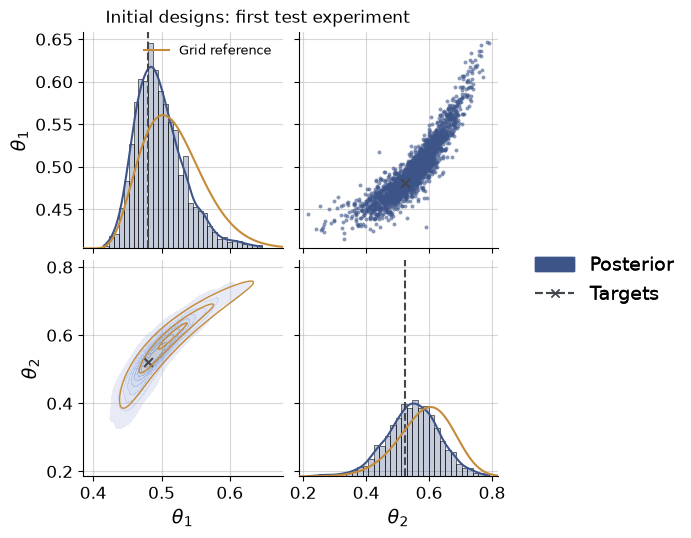

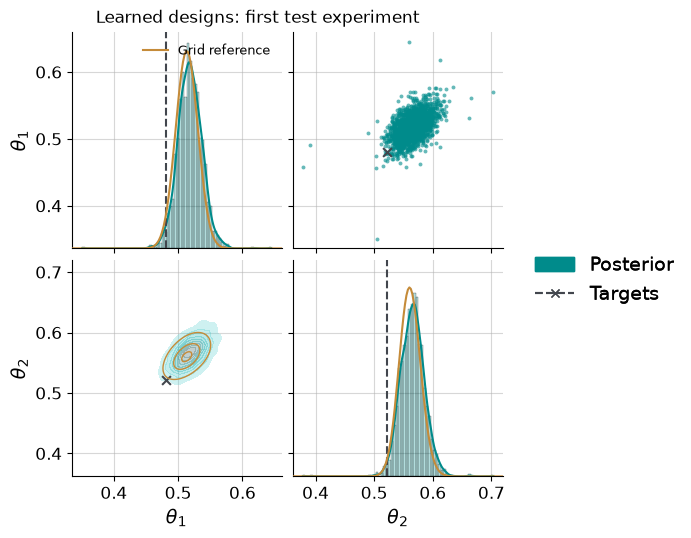

In [ ]:
axis_np = axis.cpu().numpy()
spacing = axis_np[1] - axis_np[0]

for name, color in [("Initial", colors["initial"]), ("Learned", colors["optimized"])]:

    g = bf.diagnostics.pairs_posterior(
        posterior_samples[name][0], targets=test_theta[0].cpu().numpy(),
        variable_names=[r"$\theta_1$", r"$\theta_2$"], post_color=color,
        target_color="#42464D", markersize=8, alpha=0.3, height=2.6,
    )

    limits = [ax.get_xlim() for ax in g.diag_axes]
    weights = reference_weights[name][0].reshape(len(axis_np), len(axis_np))
    g.diag_axes[0].plot(axis_np, weights.sum(axis=1) / spacing, color=colors["reference"], label="Grid reference")
    g.diag_axes[1].plot(axis_np, weights.sum(axis=0) / spacing, color=colors["reference"])
    levels = weights.max() * np.array([0.1, 0.5, 0.9])
    g.axes[1, 0].contour(axis_np, axis_np, weights.T, levels=levels, colors=colors["reference"], linewidths=1)
    g.axes[0, 0].set_xlim(limits[0])
    g.axes[1, 1].set_xlim(limits[1])
    g.axes[1, 0].set_ylim(limits[1])
    g.diag_axes[0].legend(frameon=False, fontsize=9)
    g.figure.suptitle(f"{name} designs: first test experiment", y=1.02)
    
    plt.show()

In [8]:
grid_np = grid.cpu().numpy()
rows = []
for name in posterior_samples:
    weights = reference_weights[name]
    reference_mean = weights @ grid_np
    reference_sd = np.sqrt(np.maximum(weights @ grid_np**2 - reference_mean**2, 0))
    flow_sd = posterior_samples[name].std(axis=1)
    for j in range(2):
        rows.append({
            "Design": name, "Parameter": f"theta_{j + 1}",
            "Prior SD": 0.1, "Flow SD": flow_sd[:, j].mean(),
            "Grid SD": reference_sd[:, j].mean(),
        })
pd.DataFrame(rows).round(3)

,Design,Parameter,Prior SD,Flow SD,Grid SD
0,Initial,theta_1,0.1,0.035,0.039
1,Initial,theta_2,0.1,0.084,0.084
2,Learned,theta_1,0.1,0.019,0.017
3,Learned,theta_2,0.1,0.017,0.016


The comparison separates two questions: does the flow approximate the posterior, and do the learned designs reduce uncertainty? Agreement with the grid addresses the first. The change in posterior spread addresses the second for these examples. The held-out loss above provides a broader check of the design objective.

The main ingredients are a differentiable simulator, a BayesFlow inference network, and an optimizer that updates both the network and the design variables. `rsample()` connects them.

#### References

[1] Rainforth, T., Foster, A., Ivanova, D. R., & Bickford Smith, F. (2024). Modern Bayesian experimental design. Statistical Science, 39(1), 100-114.

[2] Huan, X., Jagalur, J., & Marzouk, Y. (2024). Optimal experimental design: Formulations and computations. Acta Numerica, 33, 715-840.

[3] Barber, D., & Agakov, F. (2004). The im algorithm: a variational approach to information maximization. Advances in neural information processing systems, 16(320), 201.

[4] Foster, A., Jankowiak, M., O’Meara, M., Teh, Y. W., & Rainforth, T. (2020, June). A unified stochastic gradient approach to designing bayesian-optimal experiments. In International Conference on Artificial Intelligence and Statistics (pp. 2959-2969). PMLR.
